In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("BlinKIT Grocery Data.csv")

# Display first 5 rows
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,55.1614,5.0


In [3]:
print(df.info())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Sales                      8523 non-null   float64
 10  Rating                     8523 non-null   float64
dtypes: float64(3), int64(1), str(7)
memory usage: 1.2 MB
None


,Outlet Establishment Year,Item Visibility,Sales,Rating
count,8523.000000,8523.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,140.992783,3.965857
std,3.189396,0.051598,62.275067,0.605651
min,2011.000000,0.000000,31.290000,1.000000
25%,2014.000000,0.026989,93.826500,4.000000
50%,2016.000000,0.053931,143.012800,4.000000
75%,2018.000000,0.094585,185.643700,4.200000
max,2022.000000,0.328391,266.888400,5.000000


In [6]:
print(df.columns.tolist())

['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Sales', 'Rating']


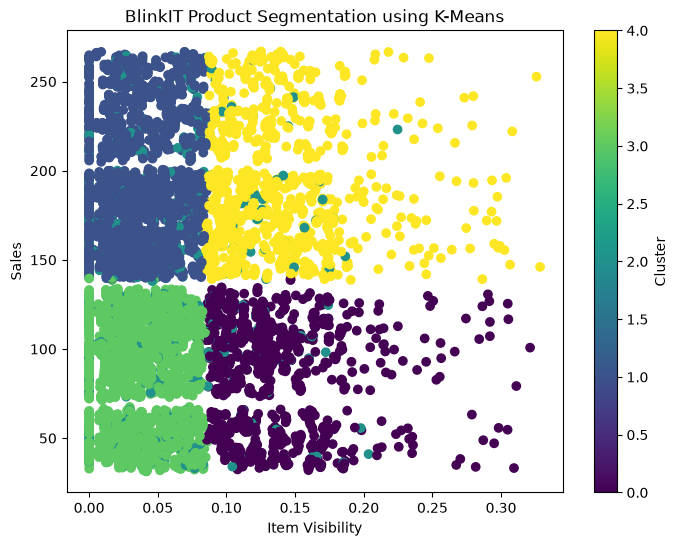

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Select features
X = df[['Item Visibility', 'Sales', 'Rating']]

# Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means Model
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Create Clusters
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Scatter Plot
plt.figure(figsize=(8, 6))

plt.scatter(
    df['Item Visibility'],
    df['Sales'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.title("BlinkIT Product Segmentation using K-Means")
plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.colorbar(label="Cluster")
plt.show()